# PERTEMUAN 8 — PRAKTIKUM PEMBELAJARAN MESIN
## **Bagaimana EDA dan preprocessing menentukan pilihan Hierarchical Clustering atau K-Means?**

**DAIS32W · 150 menit praktikum · Praktikum individual **

> **Tujuan:** Mahasiswa dapat: (a) membuktikan keterkaitan materi Pertemuan 1–7 dengan struktur clustering; (b) mengaudit apakah jarak dan model layak diuji; (c) membandingkan Ward dan K-Means dengan data, fitur dan k yang sebanding; (d) melakukan ablation dan mempertanggungjawabkan keputusan tanpa label; serta (e) menyusun portofolio satu notebook dengan tabel eksperimen dan profil cluster..

**Sebelum mulai**

1. Buka notebook di Jupyter/Google Colab/Kaggle; gunakan *Python 3* dengan `numpy`, `pandas`, `matplotlib`, `scipy`, dan `scikit-learn`.
2. Jalankan cell berurutan dari atas ke bawah. Tulis jawaban di setiap kotak **✍️ JAWABAN ANDA** (ubah sel Markdown dengan *double click*).
3. **Jangan mengubah label cultivar Wine menjadi fitur**, atau menggunakannya untuk memilih model. Cluster tidak mempunyai label benar untuk pelatihan.
4. Setiap tabel/grafik perlu diinterpretasikan. Tidak cukup hanya screenshot atau menulis “skor meningkat”.
5. **Pilih algoritma berdasarkan dua jenis bukti:** kelayakan awal dari EDA, dan hasil perbandingan yang menggunakan representasi/evaluasi setara. Hasilnya boleh berbeda dari contoh dosen bila ada penjelasan yang benar.

**Identitas:** NIM: `086` · Nama: `Gilbert Gaffin Pramudya` · Tanggal: `2026-10-30`.

### Peta hubungan teori P1–P7 dengan praktikum P8

| Materi terdahulu | Apa yang diuji dalam praktikum ini? | Bukti yang harus muncul |
|:--|:--|:--|
| **P1 — Problem framing & tipe belajar** | Kapan mencari kelompok tanpa label? Apa tujuan analisis? | Rumusan tujuan + unit analisis |
| **P2 — Vektor, matriks, jarak, objektif** | Jarak Euclidean, centroid/inertia, Ward ΔSSE | Cocokkan contoh enam Wine dari teori |
| **P3 — Desain eksperimen & generalisasi** | Perbandingan adil, satu perubahan per run, tidak memilih atas label tersembunyi | Tabel ablation + keterbatasan |
| **P4 — EDA & kualitas data** | Tipe fitur, sebaran, missing, duplikasi, outlier, korelasi | Issue log berdasar angka |
| **P5 — Cleaning & preprocessing** | Imputasi, scaling, penanganan nilai ekstrem, dampak transformasi | Hasil raw vs StandardScaler dan data terganggu |
| **P6 — Feature selection & PCA** | Redundansi, korelasi, kehilangan informasi | Perbandingan full vs selection vs PCA |
| **P7 — UTS integrasi** | Audit keputusan, eksperimen tercatat, keterulangan | FINAL_DECISION + README GitHub |

*Catatan*: Split training/validation/test tidak otomatis diwajibkan untuk **eksplorasi unsupervised deskriptif** atas satu kumpulan data. Jika metode akan diterapkan atau diklaim menggeneralisasi ke data baru, preprocessing serta evaluasi keluar-sampel harus dirancang secara terpisah. Jangan mengira bahwa cluster selalu memiliki ground truth.

## P0 — Memulai tanpa mengubah konfigurasi algoritma
**JALANKAN:** cell import, versi pustaka, dan seed. Notebook memakai dataset bawaan scikit-learn; **tidak memerlukan internet maupun CSV eksternal**. Jika `ModuleNotFoundError`, instal library pada environment Jupyter/Colab yang sesuai, lalu mulai ulang kernel.

In [1]:
import sys, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import load_wine, make_blobs, make_moons
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
import sklearn, scipy
from IPython.display import display

SEED = 2026
rng = np.random.default_rng(SEED)
OUTDIR = Path('P08_output')
OUTDIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 15)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__, '| SciPy:', scipy.__version__)
print('Random seed:', SEED, '| Output:', OUTDIR.resolve())

Python: 3.13.5 | scikit-learn: 1.8.0 | SciPy: 1.17.0
Random seed: 2026 | Output: /mnt/data/P08_output


## P1 — Dari hitungan teori ke Python
**SUMBER NYATA:** `sklearn.datasets.load_wine()` (178 sampel, 13 fitur numerik). Pengelompokan **tidak memakai** `wine.target`. Contoh dari teori memilih indeks `[0,2,59,60,175,176]` dan dua fitur (`alcohol`, `color_intensity`).

**JALANKAN:** tampilkan enam observasi, jarak A–B, dan dua skenario kelompok S1/S2. Cocokkan dengan Bagian 6 materi teori.

In [2]:
wine = load_wine(as_frame=True)
X_raw = wine.data.copy()   # HANYA fitur kimia; label cultivar wine.target tidak masuk
X_raw.index.name = 'row_id'
contoh_id = [0, 2, 59, 60, 175, 176]
contoh = X_raw.loc[contoh_id, ['alcohol', 'color_intensity']].copy()
contoh.index = list('ABCDEF')
print('Dataset:', X_raw.shape, '| Target tersedia untuk sumber, tetapi TIDAK dimasukkan ke clustering.')
display(contoh)
dist = squareform(pdist(contoh.to_numpy(), metric='euclidean'))
print('Jarak A-B =', round(dist[0,1],4), '(teori ≈ 1.0707)')
S1 = [0,0,1,1,2,2]   # A,B | C,D | E,F
S2 = [0,1,0,1,2,2]   # A,C | B,D | E,F
print('Silhouette S1 =', round(silhouette_score(contoh, S1),4), '(teori ≈ 0.686)')
print('Silhouette S2 =', round(silhouette_score(contoh, S2),4), '(teori ≈ 0.098)')
assert X_raw.shape == (178, 13)

Dataset: (178, 13) | Target tersedia untuk sumber, tetapi TIDAK dimasukkan ke clustering.


,alcohol,color_intensity
A,14.23,5.64
B,13.16,5.68
C,12.37,1.95
D,12.33,3.27
E,13.27,10.20
F,13.17,9.30


Jarak A-B = 1.0707 (teori ≈ 1.0707)
Silhouette S1 = 0.6864 (teori ≈ 0.686)
Silhouette S2 = 0.0979 (teori ≈ 0.098)


**Jawaban P1.** `S1` dan `S2` adalah dua pembagian kelompok yang berbeda atas enam observasi contoh, bukan label kelas asli. Nilai silhouette berubah karena silhouette dihitung dari jarak dalam kelompok sendiri dibandingkan kelompok terdekat; ketika pembagian anggota berubah, jarak rata-rata intra-cluster dan antar-cluster juga berubah walaupun enam titik datanya tetap sama. Pada contoh ini jarak A–B = **1,0707**, silhouette S1 = **0,6864**, sedangkan S2 = **0,0979**. Enam observasi hanya contoh perhitungan dan tidak mewakili seluruh 178 sampel dengan 13 fitur, sehingga tidak cukup untuk menyimpulkan struktur atau kualitas clustering seluruh Wine.

## P2 — EDA sebelum clustering: apakah metode berbasis jarak masuk akal?

> **Pertanyaan keputusan:** dataset berukuran berapa, fitur apa yang tersedia, adakah kualitas data bermasalah, apakah skala timpang, apakah banyak fitur redundan, dan apakah perlu mengeksplorasi hierarki?

### P2-A. Profil data dan audit missing/duplikasi
**JALANKAN:** lihat `head`, ukuran, tipe data, missing, duplikasi, rentang, dan sebaran. **Jangan langsung scaling / clustering**.

In [3]:
display(X_raw.head(5))
report_eda = pd.DataFrame({
    'dtype':X_raw.dtypes.astype(str),
    'missing':X_raw.isna().sum(),
    'mean':X_raw.mean(),
    'std':X_raw.std(ddof=0),
    'min':X_raw.min(),
    'median':X_raw.median(),
    'max':X_raw.max(),
})
report_eda['range'] = report_eda['max'] - report_eda['min']
print('Ukuran n,p:', X_raw.shape)
print('Total missing:', int(X_raw.isna().sum().sum()))
print('Duplikat persis:', int(X_raw.duplicated().sum()))
print('Fitur konstan:', list(X_raw.columns[X_raw.nunique() <= 1]))
print('Rasio rentang terbesar/terkecil =', round(report_eda['range'].max()/report_eda['range'].min(),2))
display(report_eda.round(3))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
row_id,,,,,,,,,,,,,
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ukuran n,p: (178, 13)
Total missing: 0
Duplikat persis: 0
Fitur konstan: []
Rasio rentang terbesar/terkecil = 2645.28


,dtype,missing,mean,std,min,median,max,range
alcohol,float64,0,13.001,0.810,11.03,13.050,14.83,3.80
malic_acid,float64,0,2.336,1.114,0.74,1.865,5.80,5.06
ash,float64,0,2.367,0.274,1.36,2.360,3.23,1.87
alcalinity_of_ash,float64,0,19.495,3.330,10.60,19.500,30.00,19.40
magnesium,float64,0,99.742,14.242,70.00,98.000,162.00,92.00
total_phenols,float64,0,2.295,0.624,0.98,2.355,3.88,2.90
flavanoids,float64,0,2.029,0.996,0.34,2.135,5.08,4.74
nonflavanoid_phenols,float64,0,0.362,0.124,0.13,0.340,0.66,0.53
proanthocyanins,float64,0,1.591,0.571,0.41,1.555,3.58,3.17
color_intensity,float64,0,5.058,2.312,1.28,4.690,13.00,11.72


### P2-B. Distribusi, outlier, dan seberapa timpang skala fitur?
**JALANKAN:** tinjau histogram beberapa fitur dan jumlah nilai di luar batas IQR (indikasi statistik, bukan otomatis kesalahan). Tingginya skala `proline` perlu dibandingkan dengan fitur berskala kecil.

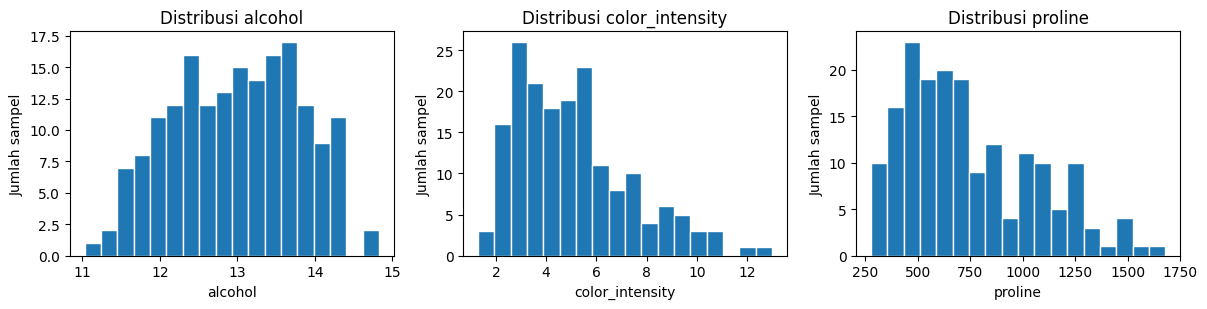

Jumlah observasi di luar batas 1.5×IQR per fitur (tidak otomatis dihapus):


,jumlah_outlier
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0


In [4]:
selected = ['alcohol', 'color_intensity', 'proline']
fig, axes = plt.subplots(1,3, figsize=(12,3.2))
for ax,col in zip(axes, selected):
    ax.hist(X_raw[col], bins=18, edgecolor='white')
    ax.set_title(f'Distribusi {col}'); ax.set_xlabel(col); ax.set_ylabel('Jumlah sampel')
plt.tight_layout(); plt.show()
q1, q3 = X_raw.quantile(.25), X_raw.quantile(.75)
iqr = q3-q1
outlier_iqr = ((X_raw.lt(q1-1.5*iqr)) | (X_raw.gt(q3+1.5*iqr))).sum()
print('Jumlah observasi di luar batas 1.5×IQR per fitur (tidak otomatis dihapus):')
display(outlier_iqr.sort_values(ascending=False).rename('jumlah_outlier').to_frame().head(8))

### P2-C. Korelasi, kedekatan, dan tampilan dua dimensi
**JALANKAN:** perhatikan korelasi absolut tertinggi, lalu bandingkan histogram jarak pasangan pada data mentah vs distandardisasi. Angka jarak antarrepresentasi **tidak dapat dibandingkan sebagai jarak bersatuan sama**. Scatter 2D hanyalah proyeksi dua fitur, bukan gambaran lengkap 13 dimensi.

Pasangan korelasi absolut terbesar:


,,abs(Pearson r)
total_phenols,flavanoids,0.864564
flavanoids,od280/od315_of_diluted_wines,0.787194
total_phenols,od280/od315_of_diluted_wines,0.699949
flavanoids,proanthocyanins,0.652692
alcohol,proline,0.643720
total_phenols,proanthocyanins,0.612413


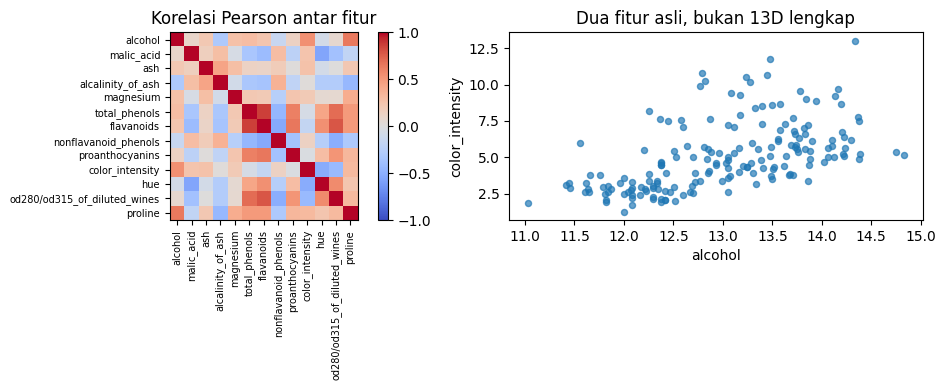

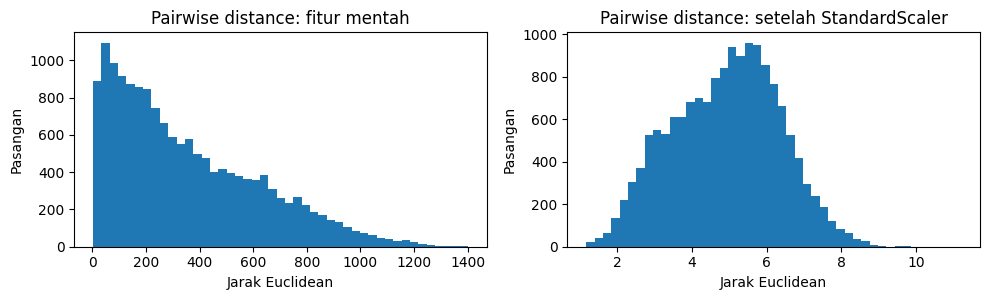

Median pairwise raw: 282.172 | standardized: 5.004


In [5]:
corr = X_raw.corr(numeric_only=True)
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
flat = upper.stack().sort_values(ascending=False)
print('Pasangan korelasi absolut terbesar:')
display(flat.head(6).rename('abs(Pearson r)').to_frame())
fig, axes=plt.subplots(1,2,figsize=(11,4))
im=axes[0].imshow(corr, vmin=-1,vmax=1,cmap='coolwarm')
axes[0].set_xticks(range(13), labels=X_raw.columns, rotation=90, fontsize=7)
axes[0].set_yticks(range(13), labels=X_raw.columns, fontsize=7)
axes[0].set_title('Korelasi Pearson antar fitur')
plt.colorbar(im,ax=axes[0],fraction=.047)
axes[1].scatter(X_raw['alcohol'],X_raw['color_intensity'],alpha=.68,s=19)
axes[1].set_title('Dua fitur asli, bukan 13D lengkap')
axes[1].set_xlabel('alcohol'); axes[1].set_ylabel('color_intensity')
plt.tight_layout();plt.show()
X_std = StandardScaler().fit_transform(X_raw)
draw, dstd = pdist(X_raw.to_numpy()), pdist(X_std)
fig,axes=plt.subplots(1,2,figsize=(10,3.1))
axes[0].hist(draw,bins=45);axes[0].set_title('Pairwise distance: fitur mentah')
axes[1].hist(dstd,bins=45);axes[1].set_title('Pairwise distance: setelah StandardScaler')
for ax in axes: ax.set_xlabel('Jarak Euclidean');ax.set_ylabel('Pasangan')
plt.tight_layout();plt.show()
print('Median pairwise raw:',round(float(np.median(draw)),3),'| standardized:',round(float(np.median(dstd)),3))

### P2-D. Issue log sebelum model pertama

| Temuan/isu data | Bukti angka/tabel dari output | Risiko untuk jarak/cluster | Keputusan sementara |
|---|---|---|---|
| 1. Jumlah dan tipe fitur | 178 baris × 13 fitur; seluruh fitur bertipe numerik `float64`; tidak ada fitur konstan | Fitur dengan rentang besar dapat mendominasi Euclidean | Gunakan StandardScaler sebagai baseline |
| 2. Missing dan duplikasi | Missing = **0**; duplikat persis = **0** | Tidak ada alasan mengimputasi atau menghapus baris pada data asli | Pertahankan data asli; simulasi missing/duplikat dilakukan terpisah pada P5 |
| 3. Rentang dan skala | Rentang `proline` = **1402** (278–1680), `hue` = **1,23** (0,48–1,71); rasio rentang terbesar/terkecil = **2645,28** | Fitur berskala besar dapat mendominasi jarak mentah | StandardScaler; bandingkan raw, standard, dan robust |
| 4. Outlier menurut IQR | Di luar 1,5×IQR: `magnesium` **4**, `alcalinity_of_ash` **4**, `color_intensity` **4**, `malic_acid` **3**, `ash` **3** | Titik ekstrem dapat mengubah jarak, centroid, atau merge Ward; indikasi statistik bukan bukti data salah | Jangan menghapus otomatis; uji clipping sebagai sensitivitas |
| 5. Korelasi/redundansi | Korelasi absolut tertinggi `total_phenols`–`flavanoids` = **0,8646**; berikutnya `flavanoids`–`od280/od315_of_diluted_wines` = **0,7872** | Fitur berkorelasi dapat memberi bobot berulang pada informasi serupa | Uji seleksi fitur dengan ambang contoh 0,80 dan catat trade-off |

**Pertanyaan kelayakan.** (1) Dendrogram berguna untuk 178 sampel karena memperlihatkan urutan merge dan membantu mengeksplorasi tingkat pemotongan hierarki. (2) Ya, skala membelokkan jarak; median jarak pasangan mentah **282,172**, sedangkan setelah standardisasi **5,004** (satuan kedua ruang berbeda, sehingga angka ini bukan perbandingan kualitas langsung). (3) Tidak; jika bentuk cluster tidak kompak, metode kompak bisa tidak cocok. (4) Centroid K-Means lebih praktis untuk segmentasi kompak dan data lebih besar saat ringkasan pusat cluster cukup, sedangkan Ward memberi riwayat penggabungan hierarkis.

**Kesimpulan EDA sementara:** dataset numerik dan lengkap, tetapi rentang fitur sangat timpang dan ada korelasi kuat. Mulai dari StandardScaler, lalu bandingkan Ward dan K-Means pada fitur serta k yang sama; jangan melakukan cleaning otomatis hanya karena terdeteksi outlier.

## P3 — Bandingkan algoritma dengan kondisi yang **sama**

**Aturan eksperimen adil:** Ward dan K-Means dibandingkan pada **X dan k yang sama**. Baseline pertama memakai `StandardScaler`, Euclidean, `k=2–5`; K-Means `n_init=20`, `random_state=2026`. `silhouette` lebih tinggi biasanya lebih baik; `DBI` lebih kecil biasanya lebih baik, tetapi keduanya tidak membuktikan makna domain.

**Konstruk kode evaluasi** (jalankan, tidak perlu mengubah kecuali diminta): `evaluate_run()` menyimpan identitas run, model, representasi, k, skor pada **ruang evaluasi standar X_std yang sama**, skor pada ruang training, DBI, ukuran cluster terkecil, dan waktu fit. Score pada ruang training berbeda hanya bersifat deskriptif, **bukan dasar membandingkan raw dengan PCA**.

In [6]:
EXPERIMENTS = []
ALL_LABELS = {}

def evaluate_run(run_id, X_fit, method='Ward', k=3, X_eval=None, notes=''):
    X_fit = np.asarray(X_fit, dtype=float)
    X_eval = X_fit if X_eval is None else np.asarray(X_eval, dtype=float)
    assert len(X_fit)==len(X_eval), 'Jumlah baris ruang fit dan evaluasi harus sama.'
    t0 = time.perf_counter()
    if method == 'Ward':
        est = AgglomerativeClustering(n_clusters=k, linkage='ward')
    elif method == 'K-Means':
        est = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED)
    else: raise ValueError('Pilih Ward atau K-Means')
    labs = est.fit_predict(X_fit)
    elapsed = time.perf_counter()-t0
    sizes = np.bincount(labs)
    sil_eval = silhouette_score(X_eval,labs) if 1<len(sizes)<len(labs) else np.nan
    dbi_eval = davies_bouldin_score(X_eval,labs) if 1<len(sizes)<len(labs) else np.nan
    sil_fit = silhouette_score(X_fit,labs) if 1<len(sizes)<len(labs) else np.nan
    # SSE/within-cluster sum of squares, dihitung untuk KEDUA metode di X_eval yang sama.
    # Hanya layak dibandingkan untuk n, k, dan ruang evaluasi yang sama.
    sse = sum(((X_eval[labs==j]-X_eval[labs==j].mean(axis=0))**2).sum()
              for j in np.unique(labs))
    row = {'run':run_id,'model':method,'k':k,'n':len(labs),'fit_dim':X_fit.shape[1],
           'silhouette_common':sil_eval,'DBI_common':dbi_eval, 'SSE_common':sse,
           'silhouette_fit_space':sil_fit,
           'min_size':int(sizes.min()),'max_size':int(sizes.max()),
           'size_pattern':str(sorted(sizes.tolist())), 'fit_seconds':elapsed,'catatan':notes}
    EXPERIMENTS.append(row)
    ALL_LABELS[run_id]=labs
    return row

print('Fungsi perbandingan siap. Nama metrik utama: silhouette_common dan DBI_common.')

Fungsi perbandingan siap. Nama metrik utama: silhouette_common dan DBI_common.


### P3-A. Baseline B1: Ward vs K-Means, data dan k sama
**JALANKAN:** 8 run (2 algoritma × k=2,3,4,5) pada Wine standar. **JAWAB:** apakah silhouette, DBI, dan ukuran cluster menunjuk metode yang sama? Apakah Ward punya manfaat non-numerik (dendrogram)?

,run,model,k,silhouette_common,DBI_common,min_size,max_size
0,B1_Ward_k2,Ward,2,0.267,1.412,56,122
1,B1_KMeans_k2,K-Means,2,0.259,1.526,87,91
2,B1_Ward_k3,Ward,3,0.277,1.419,56,64
3,B1_KMeans_k3,K-Means,3,0.285,1.389,51,65
4,B1_Ward_k4,Ward,4,0.226,1.789,28,64
5,B1_KMeans_k4,K-Means,4,0.261,1.803,27,55
6,B1_Ward_k5,Ward,5,0.187,1.923,20,64
7,B1_KMeans_k5,K-Means,5,0.237,1.644,21,57


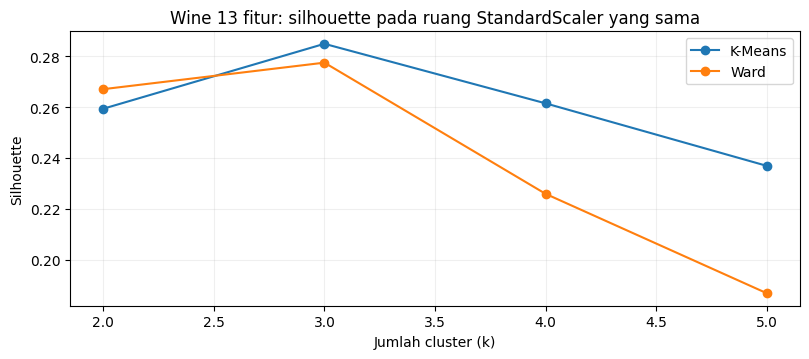

In [7]:
for k in [2,3,4,5]:
    for method in ['Ward','K-Means']:
        evaluate_run(f'B1_{method.replace("-","")}_k{k}',X_std,method,k,X_eval=X_std,notes='Wine standardized, 13 fitur')
baseline_table=pd.DataFrame(EXPERIMENTS)
display(baseline_table[['run','model','k','silhouette_common','DBI_common','min_size','max_size']].round(3))
fig,ax=plt.subplots(figsize=(8.2,3.7))
for method,sub in baseline_table.groupby('model'):
    sub=sub.sort_values('k');ax.plot(sub.k,sub.silhouette_common,marker='o',label=method)
ax.set(title='Wine 13 fitur: silhouette pada ruang StandardScaler yang sama',xlabel='Jumlah cluster (k)',ylabel='Silhouette')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

### P3-B. Dendrogram: kapan Hierarchical punya nilai tambah?
**JALANKAN:** dendrogram Wine standardized. Untuk keterbacaan, grafik menggunakan `truncate_mode='lastp'`; **semua 178 sampel tetap dipakai** untuk membentuk linkage. Cabang pada tampilan terpotong adalah agregasi, bukan observasi asli.

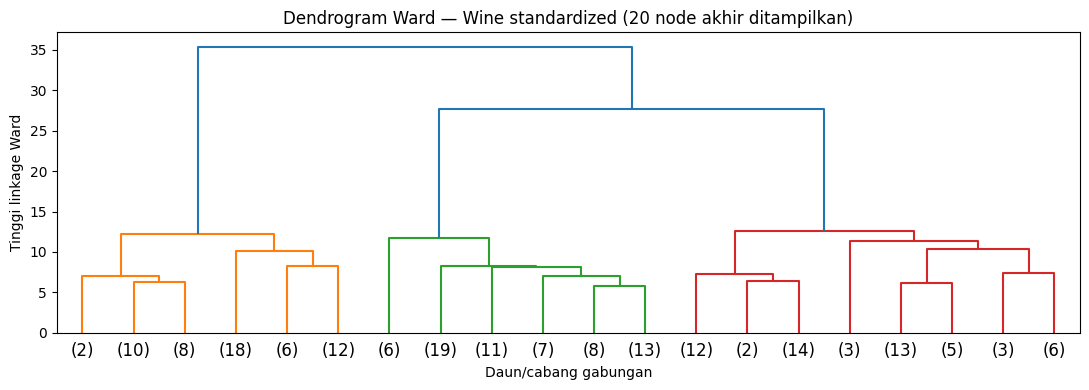

In [8]:
Z_ward = linkage(X_std, method='ward', metric='euclidean')
fig,ax=plt.subplots(figsize=(11,4))
dendrogram(Z_ward,truncate_mode='lastp',p=20,show_leaf_counts=True,ax=ax)
ax.set(title='Dendrogram Ward — Wine standardized (20 node akhir ditampilkan)',xlabel='Daun/cabang gabungan',ylabel='Tinggi linkage Ward')
plt.tight_layout();plt.show()

**Jawaban P3.** Saya memilih **k=3** sebagai konfigurasi eksploratif yang mudah dibandingkan, bukan karena k ini terbukti paling benar. Pada data Wine yang sama setelah StandardScaler, Ward menghasilkan silhouette **0,277** dan DBI **1,419**, sedangkan K-Means menghasilkan silhouette **0,285** dan DBI **1,389**. Dengan dua metrik ini, K-Means sedikit lebih baik secara numerik pada k=3 karena silhouette lebih tinggi dan DBI lebih rendah. Ukuran cluster juga relatif terbagi: Ward 56–64 anggota, K-Means 51–65 anggota. Namun selisih tersebut tidak membuktikan bahwa satu metode selalu lebih baik atau bahwa cluster memiliki makna biologis/produk tertentu. Ward tetap berguna karena dendrogram memperlihatkan proses penggabungan bertingkat dan memungkinkan struktur dilihat pada beberapa tingkat pemotongan. Sebaliknya, K-Means memberi centroid yang mudah dipakai untuk meringkas segmen. Audit P2 belum cukup menentukan algoritma terbaik: EDA hanya menguji kelayakan awal, sedangkan keputusan perlu mempertimbangkan hasil pada data dan k yang sama, stabilitas, tujuan penggunaan, serta interpretasi domain.

## P4 — Ablation: uji pengaruh materi preprocessing dan feature engineering P1–P7

**Aturan satu-perubahan:** bandingkan satu keputusan yang diubah, dengan metode dan k tetap. Gunakan `k=3` sebagai titik awal **untuk belajar mekanisme**, bukan klaim jumlah cluster optimal.

Untuk membandingkan representasi berbeda, seluruh partisi dievaluasi pada `X_std` yang sama (`silhouette_common`, `DBI_common`). Dengan ini, kita menilai apakah partisi tetap masuk akal dalam ruang 13 fitur standar. Tampilkan juga skor ruang fit untuk mempelajari sensitivitas metrik.

### P4-A. Ablation scaling: raw vs standard vs robust, Ward dan K-Means
**JALANKAN:** dataset sama; yang berubah hanya cara scaling. Jelaskan mengapa silhouette di ruang mentah bisa tinggi meskipun fitur berunit besar mendominasi.

In [9]:
X_robust = RobustScaler().fit_transform(X_raw)
for method in ['Ward','K-Means']:
    for tag,Xv in [('RAW',X_raw.to_numpy()),('STD',X_std),('ROBUST',X_robust)]:
        evaluate_run(f'P4_{method.replace("-","")}_{tag}', Xv, method, 3, X_eval=X_std,
                     notes=f'pengaruh scaling: {tag}')
rows_scaling = pd.DataFrame(EXPERIMENTS).query("run.str.startswith('P4_')",engine='python')
display(rows_scaling[['run','silhouette_common','silhouette_fit_space','DBI_common','min_size']].round(3))

,run,silhouette_common,silhouette_fit_space,DBI_common,min_size
8,P4_Ward_RAW,0.106,0.564,3.427,48
9,P4_Ward_STD,0.277,0.277,1.419,56
10,P4_Ward_ROBUST,0.275,0.256,1.389,55
11,P4_KMeans_RAW,0.108,0.571,3.364,47
12,P4_KMeans_STD,0.285,0.285,1.389,51
13,P4_KMeans_ROBUST,0.280,0.264,1.391,49


### P4-B. Ablation *feature selection*: menghapus fitur sangat berkorelasi
**JALANKAN:** fitur diseleksi dengan filter korelasi absolut `>0.80`; angka ambang dipilih sebagai contoh, **bukan aturan universal**. Dalam clustering, fitur dengan korelasi tinggi bisa tetap punya arti domain; selalu catat fitur yang dibuang.

In [10]:
THRESHOLD_R = 0.80
corr_abs = X_raw.corr().abs()
upper_only = corr_abs.where(np.triu(np.ones(corr_abs.shape),k=1).astype(bool))
to_drop = [c for c in upper_only.columns if (upper_only[c] > THRESHOLD_R).any()]
cols_keep = [c for c in X_raw.columns if c not in to_drop]
X_select = StandardScaler().fit_transform(X_raw[cols_keep])
print('Fitur dibuang:', to_drop, '| jumlah tersisa:', len(cols_keep), 'dari 13')
for method in ['Ward','K-Means']:
    evaluate_run(f'P4_{method.replace("-","")}_SELECT', X_select,method,3,X_eval=X_std,notes='Corr filter > .80')

Fitur dibuang: ['flavanoids'] | jumlah tersisa: 12 dari 13


### P4-C. Ablation PCA 90% explained variance
**JALANKAN:** standardisasi dilanjutkan PCA; cek berapa komponen yang diperlukan untuk mencapai minimal 90% variance. PCA adalah transformasi gabungan fitur, bukan pemilihan kolom asli; skor ruang PCA tidak sepenuhnya sebanding dengan skor ruang standar, maka gunakan *common evaluation space*.

PCA: dimensi 13 → 8 | retained cumulative EVR: 0.9202


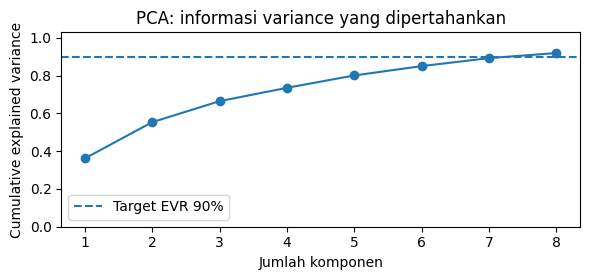

In [11]:
pca = PCA(n_components=0.90, svd_solver='full')
X_pca = pca.fit_transform(X_std)
print('PCA: dimensi', X_std.shape[1], '→', X_pca.shape[1],
      '| retained cumulative EVR:',round(float(pca.explained_variance_ratio_.sum()),4))
for method in ['Ward','K-Means']:
    evaluate_run(f'P4_{method.replace("-","")}_PCA90', X_pca, method,3,X_eval=X_std,notes='StandardScaler + PCA 90%')
fig,ax=plt.subplots(figsize=(6,2.9))
ax.plot(range(1,X_pca.shape[1]+1),np.cumsum(pca.explained_variance_ratio_),marker='o')
ax.axhline(.90,ls='--',label='Target EVR 90%')
ax.set(title='PCA: informasi variance yang dipertahankan',xlabel='Jumlah komponen',ylabel='Cumulative explained variance')
ax.set_ylim(0,1.03);ax.legend();plt.tight_layout();plt.show()

### P4-D. Ablation nilai ekstrem: clip berbasis IQR (analisis sensitivitas)
**JALANKAN:** membatasi nilai di luar 1,5×IQR sebagai **eksperimen sensitivitas**, bukan keputusan otomatis bahwa nilai ekstrem salah. Jangan mengklaim setiap perubahan skor adalah perbaikan yang sah tanpa alasan domain.

In [12]:
low, high = q1-1.5*iqr, q3+1.5*iqr
X_clip = X_raw.clip(lower=low,upper=high,axis='columns')
changed_cells = int((X_clip != X_raw).sum().sum())
X_clip_std=StandardScaler().fit_transform(X_clip)
print('Nilai sel yang berubah akibat IQR clipping:',changed_cells)
for method in ['Ward','K-Means']:
    evaluate_run(f'P4_{method.replace("-","")}_CLIP', X_clip_std,method,3,X_eval=X_std,notes='IQR clip pada fitur asli')

Nilai sel yang berubah akibat IQR clipping: 21


### P4-E. Tabel percobaan terkendali
**JALANKAN:** bandingkan **B1 k=3** dengan P4 scaling, selection, PCA, dan clipping. **JAWAB:** fitur/dimensi apa yang berubah? Apakah nilai *common* dan *fit* bergerak searah? Mengapa “skor lebih tinggi” tidak otomatis berarti metode lebih baik?

In [13]:
all_results = pd.DataFrame(EXPERIMENTS)
compare_p4=all_results[(all_results.k.eq(3)) & ((all_results.run.str.startswith('B1_')) | (all_results.run.str.startswith('P4_')))]
display(compare_p4[['run','model','fit_dim','silhouette_common','DBI_common',
                    'silhouette_fit_space','min_size','size_pattern']].round(3))

,run,model,fit_dim,silhouette_common,DBI_common,silhouette_fit_space,min_size,size_pattern
2,B1_Ward_k3,Ward,13,0.277,1.419,0.277,56,"[56, 58, 64]"
3,B1_KMeans_k3,K-Means,13,0.285,1.389,0.285,51,"[51, 62, 65]"
8,P4_Ward_RAW,Ward,13,0.106,3.427,0.564,48,"[48, 58, 72]"
9,P4_Ward_STD,Ward,13,0.277,1.419,0.277,56,"[56, 58, 64]"
10,P4_Ward_ROBUST,Ward,13,0.275,1.389,0.256,55,"[55, 56, 67]"
11,P4_KMeans_RAW,K-Means,13,0.108,3.364,0.571,47,"[47, 62, 69]"
12,P4_KMeans_STD,K-Means,13,0.285,1.389,0.285,51,"[51, 62, 65]"
13,P4_KMeans_ROBUST,K-Means,13,0.280,1.391,0.264,49,"[49, 63, 66]"
14,P4_Ward_SELECT,Ward,12,0.270,1.407,0.260,56,"[56, 59, 63]"
15,P4_KMeans_SELECT,K-Means,12,0.284,1.394,0.277,51,"[51, 63, 64]"


**Jawaban P4 — tabel ablation terkendali.** Metrik *common* mengevaluasi semua partisi pada ruang 13 fitur `X_std` yang sama.

| Dua run dibandingkan | Hanya keputusan apa yang berubah? | Perubahan metrik (angka) | Penjelasan + trade-off |
|---|---|---|---|
| `P4_KMeans_RAW` vs `P4_KMeans_STD` | Scaling raw → StandardScaler; algoritma K-Means dan k=3 sama | Silhouette common **0,108 → 0,285**; DBI common **3,364 → 1,389** | Standardisasi mengurangi dominasi fitur berskala besar. Silhouette fit raw (0,571) tampak tinggi, tetapi dihitung di ruang mentah yang didominasi skala; itu bukan dasar adil untuk mengklaim raw lebih baik. |
| `B1_KMeans_k3` vs `P4_KMeans_SELECT` | Menghapus satu fitur sangat berkorelasi (`flavanoids`); 13 → 12 fitur | Silhouette common **0,285 → 0,284**; DBI common **1,389 → 1,394** | Hasil hampir sama tetapi sedikit memburuk pada dua metrik; pengurangan redundansi tidak otomatis meningkatkan kualitas partisi. Ada trade-off berupa hilangnya sebagian informasi fitur. |
| `B1_Ward_k3` vs `P4_Ward_PCA90` | StandardScaler sama, representasi 13 fitur → 8 komponen PCA | Silhouette common **0,277 → 0,275**; DBI common **1,419 → 1,389** | PCA mempertahankan **92,02%** explained variance dengan 8 komponen. DBI sedikit membaik, tetapi silhouette sedikit turun; kombinasi linear dapat menghilangkan sebagian informasi dan komponen lebih sulit ditafsirkan sebagai fitur asli. |
| `B1_KMeans_k3` vs `P4_KMeans_CLIP` | Clipping IQR 1,5×; algoritma dan k sama | Silhouette common **0,285 → 0,285**; DBI common **1,389 → 1,389** | Pada metrik yang dibulatkan tiga desimal tidak tampak perubahan. Sebanyak **21 sel** berubah, tetapi perubahan preprocessing ini tidak memberi bukti perbaikan yang jelas. |

**Kesimpulan:** preprocessing mengubah geometri jarak dan dapat mengubah hasil clustering. Metrik perlu dibandingkan pada ruang evaluasi yang sama; skor lebih tinggi saja tidak otomatis berarti model lebih berguna, karena informasi, interpretasi, ukuran cluster, dan tujuan aplikasi tetap penting.

## P5 — Bukti dari P4–P5: apa akibat **missing, duplikasi, dan outlier**?

Wine asli tidak memiliki missing/duplikasi persis. Karena itu kita membentuk **SALINAN TERGANGGU secara sengaja**. Baris asli tidak diubah; simulasi ini **bukan karakteristik Wine asli**. Tujuannya menunjukkan prosedur cleaning dan kualitas data memengaruhi hasil clustering.

**Keputusan penting:** model clustering memerlukan matriks numerik tanpa NaN. Nilai yang hilang harus ditangani; duplikasi dapat mengubah bobot pola; outlier dapat menggeser centroid atau mengubah urutan merge. Jangan menilai preprocessing yang dipilih berdasarkan label asli Wine.

In [14]:
X_dirty = X_raw.copy()
# Sengaja menaruh missing pada beberapa sel, menduplikasi beberapa baris,
# dan membuat 1 nilai proline ekstrem; semua ini simulasi pembelajaran.
missing_rng = np.random.default_rng(SEED+11)
missing_pairs = missing_rng.choice(len(X_dirty)*3, size=20, replace=False)
for idx in missing_pairs:
    r, cidx = divmod(int(idx), 3)
    X_dirty.iloc[r, cidx] = np.nan
outlier_row=17
original_proline=float(X_dirty.iloc[outlier_row]["proline"])
X_dirty.loc[outlier_row, 'proline'] = original_proline*8
X_dirty=pd.concat([X_dirty, X_dirty.loc[[0,2,59,60]]],ignore_index=True)
print('Wine ASLI:',X_raw.shape, 'missing',int(X_raw.isna().sum().sum()),'duplikat',int(X_raw.duplicated().sum()))
print('Wine SALINAN TERGANGGU:',X_dirty.shape,'missing',int(X_dirty.isna().sum().sum()),
      'duplikat',int(X_dirty.duplicated().sum()))
print('Outlier buatan: proline row 17 sebelum',original_proline,'sesudah',original_proline*8)

Wine ASLI: (178, 13) missing 0 duplikat 0
Wine SALINAN TERGANGGU: (182, 13) missing 20 duplikat 4
Outlier buatan: proline row 17 sebelum 1130.0 sesudah 9040.0


### P5-A. Bandingkan dua penanganan: naive vs audit + cleaning
**PENTING:** `naive` memakai imputasi mean dan tetap membiarkan duplikasi serta outlier buatan. `cleaned` memakai median, menghapus duplikasi persis sebelum fit scaler, lalu clipping ringan dari kuantil 1%–99% sebagai **contoh kebijakan simulasi**, bukan aturan baku. Karena penghapusan duplikasi mengubah n, metrik antar-output tidak apple-to-apple. Untuk **bukti perbandingan adil**, model fit pada versi yang sudah dibersihkan lalu **diproyeksikan kembali pada 178 baris bersih asli** tidak trivial untuk Ward yang tidak punya `predict`. Karena itu bagian ini fokus pada perubahan hasil, jumlah anggota, dan audit kualitas; **jangan membandingkan angka antar-n secara langsung untuk menyatakan menang**.

In [15]:
X_dirty_naive=SimpleImputer(strategy='mean').fit_transform(X_dirty)
X_dirty_naive_std=StandardScaler().fit_transform(X_dirty_naive)
X_dirty_dedup=X_dirty.drop_duplicates().copy()
X_dirty_median=pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_dirty_dedup),columns=X_raw.columns)
ql=X_dirty_median.quantile(.01); qh=X_dirty_median.quantile(.99)
X_dirty_clean=X_dirty_median.clip(lower=ql,upper=qh,axis='columns')
X_dirty_clean_std=StandardScaler().fit_transform(X_dirty_clean)
for tag,Xv in [('DIRTY_MEAN_NO_CLEAN',X_dirty_naive_std),('CLEAN_MEDIAN_CLIP',X_dirty_clean_std)]:
    for method in ['Ward','K-Means']:
        evaluate_run(f'P5_{method.replace("-","")}_{tag}',Xv,method,3,X_eval=Xv,
                     notes='DATA SIMULASI TERGANGGU; n bisa berubah')
P5_table=pd.DataFrame(EXPERIMENTS)
display(P5_table[P5_table.run.str.startswith('P5_')][['run','n','silhouette_fit_space','DBI_common','min_size','max_size']].round(3))

,run,n,silhouette_fit_space,DBI_common,min_size,max_size
20,P5_Ward_DIRTY_MEAN_NO_CLEAN,182,0.252,1.507,51,74
21,P5_KMeans_DIRTY_MEAN_NO_CLEAN,182,0.261,1.463,50,73
22,P5_Ward_CLEAN_MEDIAN_CLIP,178,0.280,1.403,55,62
23,P5_KMeans_CLEAN_MEDIAN_CLIP,178,0.289,1.363,50,68


### P5-B. **Ablation yang lebih adil:** satu masalah data dalam satu waktu, jumlah baris tetap 178

**JALANKAN:** supaya perubahan bisa diatribusikan lebih jelas, buat tiga dataset dengan baris sama: (i) **original**, (ii) **missing 20 sel lalu median imputation**, (iii) **satu outlier buatan pada `proline`**. Bandingkan partisi pada `X_std` asli yang **sama**. Ini mengisolasi dampak yang lebih spesifik daripada P5-A.

In [16]:
X_miss_only=X_raw.copy()
for idx in missing_pairs:
    r,cidx=divmod(int(idx),3)
    X_miss_only.iloc[r,cidx]=np.nan
X_miss_imp=SimpleImputer(strategy='median').fit_transform(X_miss_only)
X_miss_std=StandardScaler().fit_transform(X_miss_imp)
X_outlier_only=X_raw.copy()
X_outlier_only.loc[outlier_row,'proline']=original_proline*8
X_outlier_std=StandardScaler().fit_transform(X_outlier_only)
for tag,arr in [('ORIGINAL',X_std),('MISSING_MEDIAN',X_miss_std),('OUTLIER_X8',X_outlier_std)]:
    for method in ['Ward','K-Means']:
        evaluate_run(f'P5_ISOLATED_{method.replace("-","")}_{tag}',arr,method,3,X_eval=X_std,
                     notes='n=178, data simulasi, evaluasi X_std original')
isolated=pd.DataFrame(EXPERIMENTS)
display(isolated[isolated.run.str.startswith('P5_ISOLATED')][['run','n','silhouette_common',
           'DBI_common','SSE_common','min_size']].round(3))

,run,n,silhouette_common,DBI_common,SSE_common,min_size
24,P5_ISOLATED_Ward_ORIGINAL,178,0.277,1.419,1305.049,56
25,P5_ISOLATED_KMeans_ORIGINAL,178,0.285,1.389,1277.928,51
26,P5_ISOLATED_Ward_MISSING_MEDIAN,178,0.277,1.405,1294.071,52
27,P5_ISOLATED_KMeans_MISSING_MEDIAN,178,0.284,1.398,1283.557,50
28,P5_ISOLATED_Ward_OUTLIER_X8,178,0.260,1.439,1324.403,56
29,P5_ISOLATED_KMeans_OUTLIER_X8,178,0.278,1.400,1284.059,51


**Jawaban P5.** Missing harus ditangani sebelum menghitung Euclidean karena NaN membuat jarak tidak terdefinisi/ditangani tidak sesuai oleh estimator. Duplikasi dapat memberi bobot tambahan pada pola yang sama; pada K-Means titik duplikat ikut memengaruhi rata-rata sehingga dapat menarik centroid dan mengubah pembagian anggota. Nilai sangat besar tidak pasti salah: bisa merupakan observasi valid, sehingga perlu pemeriksaan konteks/domain dan uji sensitivitas, bukan penghapusan otomatis. Pada data asli Wine terdapat **178 × 13**, **0 missing**, dan **0 duplikat**. P5 membuat salinan simulasi menjadi **182 baris**, **20 sel missing**, **4 duplikat**, dan mengalikan `proline` pada satu baris dari **1130 menjadi 9040**. Dalam ablation terisolasi dengan n=178, K-Means pada data original memiliki silhouette common **0,285** dan DBI **1,389**; dengan missing yang diimputasi median menjadi **0,284** dan **1,398**; dengan outlier buatan menjadi **0,278** dan **1,400**. Ini menunjukkan dampak yang berbeda-beda, bukan jaminan cleaning tertentu selalu memperbaiki hasil. Skor pada n berbeda tidak apple-to-apple karena jumlah observasi dan bobot pola berubah; pada P5-A, versi naive n=182 dan cleaned n=178, sehingga selisih skor tidak dapat diatribusikan hanya pada kualitas cleaning.

## P6 — Dua kondisi data: kapan Ward, kapan K-Means?

### Kasus A — Wine asli, 178 × 13, tujuan memahami struktur bertingkat

**EDA berkata:** dataset relatif terkelola, fitur numerik, skala sangat berbeda, ada beberapa korelasi tinggi, dan tujuan *eksplorasi hierarki* dapat dibantu dendrogram. Karena itu **Ward layak diuji**. Namun jika yang dicari hanya segmen kompak, K-Means juga layak. Tabel P3 menentukan apakah ada trade-off kualitas numerik dengan nilai dendrogram.

### Kasus B — 3.000 titik **SINTETIS**, kelompok kompak, tujuan segmentasi praktis

Dataset di bawah **bukan data riil** dan tidak digunakan untuk klaim tentang Wine. Fungsi `make_blobs` hanya menghasilkan dua fitur numerik dan kelompok kompak supaya mudah memahami apakah metode centroid memiliki alasan desain yang kuat. Parameter `centers` diketahui oleh pembuat contoh, tetapi label generator **tidak** dimasukkan ke model.

**JALANKAN:** EDA singkat data besar, uji K-Means semua baris, perkirakan pertumbuhan kebutuhan memori matriks jarak. Untuk benchmark adil kualitas K-Means vs Ward, gunakan **subsample yang sama** (`n=450`) dan k yang sama. Keputusan skala besar berlandaskan kebutuhan proses, biaya, dan sifat data—bukan klaim bahwa Ward tidak bisa dijalankan.

EDA data sintetis: (3000, 2) missing: 0 duplicate: 0


,fitur_x,fitur_y
min,-10.44,-7.34
median,1.03,-0.89
std,5.07,3.54
max,12.37,7.86


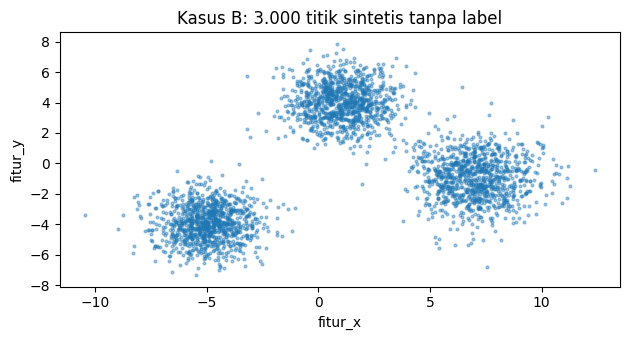

n=  178 | n×n float64 kira-kira     0.2 MB | condensed distances     0.1 MB
n=  450 | n×n float64 kira-kira     1.5 MB | condensed distances     0.8 MB
n= 3000 | n×n float64 kira-kira    68.7 MB | condensed distances    34.3 MB
n=10000 | n×n float64 kira-kira   762.9 MB | condensed distances   381.4 MB
Estimasi memori HANYA matriks jarak: bukan total memory atau jaminan alokasi dari library.


In [17]:
X_big, _labels_generator_dilarang = make_blobs(
    n_samples=3000, centers=[[-5,-4],[1,4],[7,-1]], cluster_std=[1.15,1.2,1.4],
    random_state=SEED, n_features=2)
# Label generator tidak digunakan untuk fit atau memilih hasil.
big = pd.DataFrame(X_big,columns=['fitur_x','fitur_y'])
print('EDA data sintetis:',big.shape, 'missing:',big.isna().sum().sum(),
      'duplicate:',big.duplicated().sum())
display(big.agg(['min','median','std','max']).round(2))
fig,ax=plt.subplots(figsize=(6.4,3.5))
ax.scatter(big.fitur_x,big.fitur_y,s=4,alpha=.4)
ax.set(title='Kasus B: 3.000 titik sintetis tanpa label',xlabel='fitur_x',ylabel='fitur_y');plt.tight_layout();plt.show()
for n in [178, 450, 3000, 10000]:
    full_mb=(n*n*8)/(1024*1024)
    condensed_mb=(n*(n-1)/2*8)/(1024*1024)
    print(f'n={n:5d} | n×n float64 kira-kira {full_mb:7.1f} MB | condensed distances {condensed_mb:7.1f} MB')
print('Estimasi memori HANYA matriks jarak: bukan total memory atau jaminan alokasi dari library.')

In [18]:
X_big_std=StandardScaler().fit_transform(big)
# n=450 sama untuk benchmark kualitas (menggunakan random sample index yang pasti)
idx_sampel=np.random.default_rng(SEED).choice(len(X_big_std),size=450,replace=False)
X_sample=X_big_std[idx_sampel]
for method in ['Ward','K-Means']:
    evaluate_run(f'P6_SMALL_{method.replace("-","")}',X_sample,method,3,X_eval=X_sample,
                 notes='perbandingan n=450 data sintetis dengan ruang/k sama')
# n=3000: K-Means dipakai karena tujuan partitioning praktis; bukan mengklaim Ward mustahil
large_record=evaluate_run('P6_LARGE_KMeans',X_big_std,'K-Means',3,X_eval=X_big_std,
               notes='segmen kompak n=3000, k ditentukan; Ward tidak wajib pada data besar')
P6_table=pd.DataFrame(EXPERIMENTS)
display(P6_table[P6_table.run.str.startswith('P6_')][['run','n','silhouette_common',
          'DBI_common','min_size','fit_seconds']].round(3))

,run,n,silhouette_common,DBI_common,min_size,fit_seconds
30,P6_SMALL_Ward,450,0.715,0.406,137,0.003
31,P6_SMALL_KMeans,450,0.715,0.405,137,0.019
32,P6_LARGE_KMeans,3000,0.723,0.397,994,0.018


| Aspek | Kasus A: Wine nyata | Kasus B: data sintetis 3.000 titik |
|---|---|---|
| Tujuan analisis | Eksplorasi struktur 178 sampel Wine, termasuk kemungkinan tingkat hierarki | Segmentasi praktis data sintetis dengan kelompok kompak |
| EDA: jumlah & jenis fitur | **178 × 13**, semuanya numerik; missing 0, duplikat 0; rentang fitur timpang | **3000 × 2**, fitur numerik `fitur_x` dan `fitur_y`; missing 0, duplikat 0 |
| Bukti struktur/kepraktisan | Korelasi `total_phenols`–`flavanoids` = **0,8646**; rentang `proline` = **1402**, sehingga scaling penting | Rentang observasi `fitur_x` sekitar **−10,44 hingga 12,37** dan `fitur_y` **−7,34 hingga 7,86**; data dibuat sintetis dengan tiga pusat kompak |
| Biaya komputasi & manfaat dendrogram | Ward dapat memberi riwayat merge untuk n=178; estimasi matriks jarak penuh n×n sekitar **0,2 MB** (estimasi sederhana, bukan total memori) | Untuk n=3000, matriks n×n float64 sekitar **68,7 MB** dan condensed distances **34,3 MB**; centroid K-Means memudahkan segmentasi tanpa perlu menyimpan hierarki penuh |
| Nilai hasil pembanding adil | Pada k=3 dan X_std sama: Ward silhouette **0,277**, DBI **1,419**; K-Means silhouette **0,285**, DBI **1,389** | Pada subsample sama n=450 dan k=3: Ward silhouette **0,715**, DBI **0,406**; K-Means **0,715**, DBI **0,405**. K-Means n=3000: silhouette **0,723**, DBI **0,397** |
| **Metode pilihan sementara + alasan** | Ward untuk konfigurasi final eksploratif karena dendrogram dan struktur bertingkat berguna; secara numerik K-Means sedikit lebih baik pada k=3, jadi alternatif itu tetap wajar | K-Means untuk seluruh 3000 titik karena tujuan segmentasi kompak dapat diringkas dengan centroid; pada subsample adil kualitas metrik hampir setara, sedangkan Ward menambah biaya untuk hierarki yang tidak dibutuhkan |

**Interpretasi:** K-Means tidak dipilih hanya karena jumlah baris lebih besar. Alasannya adalah kebutuhan aplikasi tidak memerlukan riwayat merge dan centroid cukup untuk segmen kompak. Benchmark n=450 menunjukkan kualitas hampir sama; pilihan praktis mempertimbangkan tujuan, biaya, dan interpretabilitas.

### P6-C (opsional) — Ketika keduanya belum tentu cocok
**JALANKAN bila waktu cukup:** data bulan sabit sintetis (*make_moons*). Clustering yang hanya mencari kelompok kompak atau menggabungkan berdasarkan Ward mungkin tidak mengikuti bentuk melengkung. Ini pengantar alasan mempelajari **DBSCAN pada Pertemuan 9**. Jangan memaksakan “hierarchical vs K-Means” jika karakter data mengisyaratkan kebutuhan metode lain.

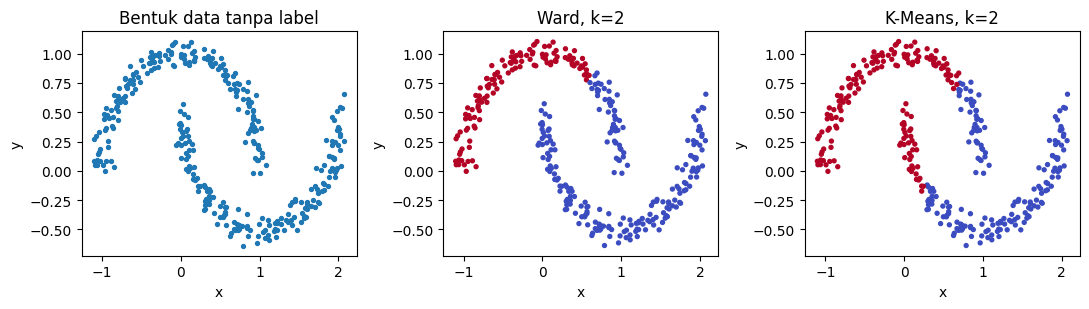

In [19]:
X_moon,_ = make_moons(n_samples=350,noise=0.06,random_state=SEED)
fig,axes=plt.subplots(1,3,figsize=(11,3.2))
axes[0].scatter(X_moon[:,0],X_moon[:,1],s=8);axes[0].set_title('Bentuk data tanpa label')
for ax,met in zip(axes[1:],['Ward','K-Means']):
    if met=='Ward': labs=AgglomerativeClustering(n_clusters=2,linkage='ward').fit_predict(X_moon)
    else: labs=KMeans(n_clusters=2,n_init=20,random_state=SEED).fit_predict(X_moon)
    ax.scatter(X_moon[:,0],X_moon[:,1],c=labs,s=8,cmap='coolwarm')
    ax.set_title(f'{met}, k=2')
for ax in axes: ax.set_xlabel('x');ax.set_ylabel('y')
plt.tight_layout();plt.show()

## P7 — Keputusan akhir, interpretasi cluster, dan portofolio

### P7-A. Tentukan konfigurasi final berdasarkan **bukti**
**WAJIB:** Pilih satu dari Ward/K-Means untuk Wine. Ubah nilai konfigurasi jika beralasan. Anda boleh memilih metode yang tidak paling tinggi silhouette-nya asalkan pilihan bermotivasi, transparan, dan mempertimbangkan kebutuhan pengguna.

**EDIT BLOK INI:** pilih kombinasi yang benar-benar Anda ujikan. Opsinya: `scaler = 'StandardScaler' / 'RobustScaler' / 'NONE'`; `representation = 'ALL' / 'CORR' / 'PCA90'`; `clip_iqr = True/False`; model `Ward`/`K-Means`, `k=2–5`. Sel final akan **benar-benar membangun transformasi pilihan Anda**, bukan hanya menuliskan namanya. `PCA90` harus disertai scaling agar variasi tidak dikuasai satuan fitur.

In [20]:
FINAL_CONFIG = {
    'dataset': 'Wine asli; 178 observasi; 13 fitur numerik; tanpa label',
    'scaler':'StandardScaler',  # EDIT: StandardScaler / RobustScaler / NONE
    'representation':'ALL',   # EDIT: ALL / CORR / PCA90
    'clip_iqr':False,         # EDIT: True atau False
    'method':'Ward',          # EDIT: Ward atau K-Means
    'k':3,                    # EDIT: 2,3,4,5
    'seed': SEED,
    'reason':'Memilih Ward untuk mengeksplorasi struktur merge hierarkis pada 178 sampel setelah standardisasi; pada k=3 silhouette 0.2774 dan DBI 1.4186, sedikit di bawah K-Means (0.285 dan 1.389), sehingga pilihan ini berorientasi pada manfaat dendrogram, bukan keunggulan metrik. k=3 bersifat eksploratif.',  # WAJIB EDIT
}
assert FINAL_CONFIG['method'] in ['Ward','K-Means']
assert FINAL_CONFIG['k'] in [2,3,4,5]
assert FINAL_CONFIG['scaler'] in ['StandardScaler','RobustScaler','NONE']
assert FINAL_CONFIG['representation'] in ['ALL','CORR','PCA90']
base_final=X_raw.copy()
if FINAL_CONFIG['clip_iqr']:
    base_final=base_final.clip(lower=low,upper=high,axis='columns')
if FINAL_CONFIG['representation']=='CORR':
    base_final=base_final[cols_keep]
if FINAL_CONFIG['scaler']=='StandardScaler':
    X_final_fit=StandardScaler().fit_transform(base_final)
elif FINAL_CONFIG['scaler']=='RobustScaler':
    X_final_fit=RobustScaler().fit_transform(base_final)
else:
    X_final_fit=base_final.to_numpy()
if FINAL_CONFIG['representation']=='PCA90':
    assert FINAL_CONFIG['scaler']!='NONE', 'PCA90 perlu scaling pada praktikum ini.'
    X_final_fit=PCA(n_components=.90,svd_solver='full').fit_transform(X_final_fit)
if FINAL_CONFIG['method']=='Ward':
    final_labels=AgglomerativeClustering(n_clusters=FINAL_CONFIG['k'],linkage='ward').fit_predict(X_final_fit)
else:
    final_labels=KMeans(n_clusters=FINAL_CONFIG['k'],n_init=20,random_state=SEED).fit_predict(X_final_fit)
print('Final configuration:',FINAL_CONFIG)
print('Fitur keluaran transformasi:',X_final_fit.shape[1])
print('Silhouette pada ruang fit:',round(silhouette_score(X_final_fit,final_labels),4))
print('Silhouette pada ruang evaluasi original standardized:',round(silhouette_score(X_std,final_labels),4))
print('DBI common:',round(davies_bouldin_score(X_std,final_labels),4))
print('Jumlah anggota:',pd.Series(final_labels).value_counts().sort_index().to_dict())

Final configuration: {'dataset': 'Wine asli; 178 observasi; 13 fitur numerik; tanpa label', 'scaler': 'StandardScaler', 'representation': 'ALL', 'clip_iqr': False, 'method': 'Ward', 'k': 3, 'seed': 2026, 'reason': 'Memilih Ward untuk mengeksplorasi struktur merge hierarkis pada 178 sampel setelah standardisasi; pada k=3 silhouette 0.2774 dan DBI 1.4186, sedikit di bawah K-Means (0.285 dan 1.389), sehingga pilihan ini berorientasi pada manfaat dendrogram, bukan keunggulan metrik. k=3 bersifat eksploratif.'}
Fitur keluaran transformasi: 13
Silhouette pada ruang fit: 0.2774
Silhouette pada ruang evaluasi original standardized: 0.2774
DBI common: 1.4186
Jumlah anggota: {0: 58, 1: 56, 2: 64}


### P7-B. Profil cluster harus dibaca pada satuan **fitur asli**
**JALANKAN:** rata-rata `alcohol`, `color_intensity`, `proline`, dan fitur lain per cluster. Warna atau nomor cluster tidak mempunyai makna kelas. Jangan memberi label normatif “baik/buruk” tanpa domain.

**Interpretasi profil final:** Cluster 0 berjumlah **58** dengan rata-rata `alcohol` **12,204**, `color_intensity` **2,895**, dan `proline` **501,431**. Cluster 1 berjumlah **56** dengan rata-rata **13,062**, **6,850**, dan **624,946**. Cluster 2 berjumlah **64** dengan rata-rata **13,669**, **5,450**, dan **1076,047**. Ini menunjukkan profil numerik yang berbeda pada tiga fitur yang ditampilkan, tetapi cluster ID hanyalah penanda dan tidak berarti kelas cultivar tertentu; tidak ada label target yang dipakai untuk membangun atau menamai cluster.


,jumlah,alcohol,color_intensity,proline
cluster,,,,
0,58,12.204,2.895,501.431
1,56,13.062,6.850,624.946
2,64,13.669,5.450,1076.047


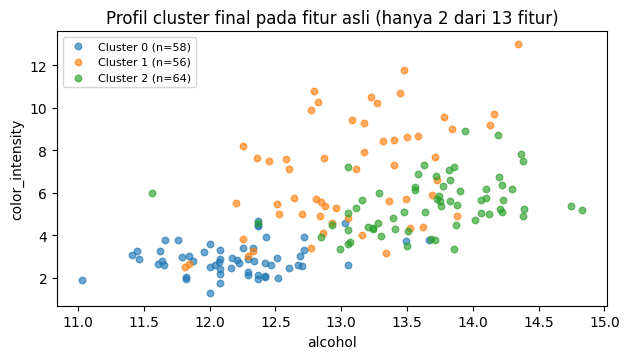

In [21]:
profile=X_raw.copy()
profile['cluster']=final_labels
size_profile=profile.groupby('cluster').size().rename('jumlah')
means_profile=profile.groupby('cluster')[['alcohol','color_intensity','proline']].mean()
cluster_profile=pd.concat([size_profile,means_profile],axis=1).round(3)
display(cluster_profile)
fig,ax=plt.subplots(figsize=(6.4,3.7))
for c,g in profile.groupby('cluster'):
    ax.scatter(g.alcohol,g.color_intensity,alpha=.65,s=22,label=f'Cluster {c} (n={len(g)})')
ax.set(title='Profil cluster final pada fitur asli (hanya 2 dari 13 fitur)',xlabel='alcohol',ylabel='color_intensity')
ax.legend(fontsize=8);plt.tight_layout();plt.show()

### P7-C. Export tabel, konfigurasi, dan README untuk portofolio GitHub
**JALANKAN:** empat berkas dibuat otomatis pada folder `P08_output`. Setelah itu lengkapi laporan Markdown pada notebook. **README bawaan masih kerangka**, bukan kesimpulan pribadi; wajib diperbaiki sebelum publikasi.

In [22]:
import json
res=pd.DataFrame(EXPERIMENTS)
res.to_csv(OUTDIR/'P08_experiment_table.csv',index=False)
cluster_profile.to_csv(OUTDIR/'P08_cluster_profile.csv')
with open(OUTDIR/'P08_final_config.json','w',encoding='utf-8') as fh:
    json.dump(FINAL_CONFIG,fh,ensure_ascii=False,indent=2)
readme = f"""# P08 — Memilih Hierarchical atau K-Means berdasarkan EDA

**Dataset utama:** scikit-learn Wine, 178 sampel × 13 fitur numerik. Label target tidak digunakan.

## Pertanyaan proyek
Bagaimana pilihan scaling, feature selection, PCA, dan konteks pemakaian memengaruhi pemilihan Ward atau K-Means?

## Alur eksperimen
Audit data → baseline fair comparison → ablation → simulasi kualitas data → keputusan akhir → profil cluster.

## Keputusan final (perlu Anda jelaskan kembali dengan angka)
- Metode: {FINAL_CONFIG['method']}
- k: {FINAL_CONFIG['k']}
- Scaling: {FINAL_CONFIG['scaler']}
- Representasi: {FINAL_CONFIG['representation']}
- Clipping IQR: {FINAL_CONFIG['clip_iqr']}
- Silhouette pada ruang StandardScaler: {silhouette_score(X_std,final_labels):.4f}
- DBI pada ruang StandardScaler: {davies_bouldin_score(X_std,final_labels):.4f}
- Alasan: Ward dipilih untuk eksplorasi struktur merge hierarkis pada 178 sampel; metriknya silhouette 0.2774 dan DBI 1.4186, sementara K-Means sedikit lebih baik secara numerik (0.285 dan 1.389). Pilihan Ward berorientasi pada manfaat dendrogram, bukan klaim unggul universal.

## Bukti
- Notebook utama `.ipynb` (soal, kode, output, interpretasi)
- `P08_experiment_table.csv`
- `P08_cluster_profile.csv`
- `P08_final_config.json`

## Keterbatasan
- Hasil sensitif terhadap scaling dan representasi; raw, selection, PCA, dan clipping tidak otomatis lebih baik.
- k=3 adalah pilihan eksploratif, bukan k optimal universal.
- Nomor cluster bukan label kelas; profil fitur tidak membuktikan sebab-akibat atau nilai normatif.
- Outlier IQR tidak selalu kesalahan, dan P5 adalah simulasi gangguan, bukan kondisi Wine asli.
- Satu seed dan satu dataset tidak menjamin stabilitas maupun generalisasi.

## Reproduksi
Python 3; NumPy; Pandas; SciPy; scikit-learn; Matplotlib. Jalankan notebook dari atas sampai bawah.
"""
(OUTDIR/'README_PORTOFOLIO_P08.md').write_text(readme,encoding='utf-8')
print('Berkas dibuat:')
for f in sorted(OUTDIR.iterdir()):print('-',f)

Berkas dibuat:
- P08_output/P08_cluster_profile.csv
- P08_output/P08_experiment_table.csv
- P08_output/P08_final_config.json
- P08_output/README_PORTOFOLIO_P08.md


### ✍️ LAPORAN AKHIR

**L1. Rumusan masalah (2–3 kalimat):** Apa objek dan tujuan pengelompokan? Mengapa clustering, bukan classification?

Objek analisis adalah 178 sampel Wine dengan 13 fitur kimia numerik. Tujuannya mengeksplorasi kelompok berdasarkan kemiripan fitur tanpa menggunakan label cultivar sebagai masukan. Clustering dipilih karena fokusnya menemukan struktur tanpa label yang digunakan untuk melatih model, bukan memprediksi kelas yang sudah diketahui.

**L2. Ringkasan EDA:** kutip minimal lima temuan angka dan satu keputusan preprocessing yang mengikuti temuan tersebut.

EDA menemukan: (1) ukuran data **178 × 13**; (2) seluruh fitur numerik `float64`; (3) missing **0** dan duplikat persis **0**; (4) rentang `proline` **1402** (278–1680); (5) rasio rentang fitur terbesar terhadap terkecil **2645,28**; (6) terdapat **4** nilai di luar batas 1,5×IQR pada `magnesium`, **4** pada `alcalinity_of_ash`, dan **4** pada `color_intensity`; (7) korelasi tertinggi `total_phenols`–`flavanoids` = **0,8646**; (8) median jarak pasangan mentah **282,172**, dibanding **5,004** setelah standardisasi. Karena skala sangat timpang, StandardScaler dipilih sebagai baseline. Outlier tidak otomatis dibuang dan korelasi diuji lewat ablation.

**L3. Ablation P1–P7:** sebutkan sedikitnya tiga eksperimen sah, perubahan masing-masing, metrik pada ruang evaluasi yang sama, serta pengaruh terhadap interpretasi.

Pada k=3 dan evaluasi common yang sama: (1) K-Means raw → StandardScaler mengubah silhouette **0,108 → 0,285** dan DBI **3,364 → 1,389**, menunjukkan skala fitur mentah mendominasi jarak. (2) K-Means full 13 fitur → seleksi 12 fitur dengan membuang `flavanoids` menghasilkan silhouette **0,285 → 0,284** dan DBI **1,389 → 1,394**, sehingga penghapusan fitur berkorelasi tidak otomatis memperbaiki partisi. (3) Ward full → PCA90 (13 → 8 komponen, explained variance **92,02%**) mengubah silhouette **0,277 → 0,275** dan DBI **1,419 → 1,389**; metrik bergerak tidak searah dan interpretasi fitur menjadi kurang langsung. (4) K-Means original → outlier buatan `proline ×8` pada n=178 mengubah silhouette **0,285 → 0,278** dan DBI **1,389 → 1,400**. Angka ini menunjukkan sensitivitas, bukan bukti semua nilai ekstrem harus dihapus.

**L4. Mengapa memilih Ward/K-Means untuk Wine?** Sebutkan k dan minimal dua metrik numerik. Jelaskan peran dendrogram atau centroid, biaya komputasi, dan apakah alternatif berbeda mungkin tetap wajar.

Konfigurasi final eksploratif memakai **Ward, k=3, StandardScaler, 13 fitur, tanpa clipping**. Pada ruang evaluasi standar, silhouette = **0,2774** dan DBI = **1,4186**, dengan ukuran cluster **58, 56, dan 64**. Dendrogram membantu melihat urutan merge dan mempertimbangkan beberapa tingkat pemotongan pada 178 sampel. Namun K-Means pada k=3 memperoleh silhouette **0,285** dan DBI **1,389**, sedikit lebih baik secara numerik. Maka K-Means juga merupakan alternatif yang wajar jika tujuan utamanya segmen kompak dan centroid. Pilihan Ward di sini berorientasi eksplorasi hierarki, bukan klaim bahwa Ward unggul pada metrik.

**L5. Dua kondisi data:** bandingkan kesimpulan Wine nyata dengan data besar sintetis.

Wine nyata berukuran **178 × 13**, dengan skala fitur timpang dan korelasi yang perlu ditangani melalui standardisasi serta evaluasi ablation. Pada data sintetis kompak **3000 × 2**, benchmark pada subsample yang sama (n=450, k=3) menghasilkan silhouette **0,715** untuk Ward dan K-Means, dengan DBI **0,406** dan **0,405**. K-Means seluruh n=3000 memperoleh silhouette **0,723** dan DBI **0,397**. Matriks jarak penuh float64 n=3000 diperkirakan **68,7 MB** (belum termasuk overhead). Karena aplikasi sintetis hanya membutuhkan segmentasi kompak, centroid K-Means lebih praktis; Ward tetap dapat dipertimbangkan jika hierarki memang dibutuhkan. Data sintetis ini tidak menjadi bukti tentang Wine nyata.

**L6. Analisis keterbatasan & penggunaan bertanggung jawab (minimal 3).**

Pertama, hasil sensitif terhadap representasi dan skala; karena itu raw, StandardScaler, RobustScaler, seleksi fitur, PCA, dan clipping dibandingkan dengan evaluasi common. Kedua, k=3 adalah pilihan eksploratif, bukan jumlah cluster yang benar secara universal; k lain memberi ukuran dan skor berbeda. Ketiga, cluster ID hanyalah nomor dan profil `alcohol`, `color_intensity`, serta `proline` tidak membenarkan label normatif atau kesimpulan sebab-akibat. Keempat, outlier berbasis IQR tidak selalu kesalahan; keputusan menghapus atau clipping perlu konteks domain. Kelima, data terganggu P5 adalah simulasi, bukan karakteristik Wine asli. Terakhir, hasil pada satu dataset dan satu seed tidak menjamin stabilitas atau generalisasi ke data baru; perlu analisis kestabilan dan validasi pada data penggunaan nyata.

**L7. Refleksi profesional (3–5 kalimat):** Apa satu keputusan yang berubah setelah melihat EDA/hasil eksperimen? Bagaimana memverifikasinya?

Awalnya, fitur mentah bisa terlihat layak karena silhouette fit pada K-Means raw mencapai **0,571**. Setelah memeriksa bahwa rasio rentang fitur adalah **2645,28** dan skor common raw hanya **0,108**, saya memilih StandardScaler untuk baseline yang lebih adil. Saya memverifikasi keputusan dengan menjalankan raw dan StandardScaler pada data, algoritma, serta k yang sama dan membandingkan keduanya pada ruang evaluasi standar. Hasil common membaik menjadi silhouette **0,285** dan DBI **1,389** pada K-Means. Saya tetap tidak menyebut skor sebagai bukti makna domain atau keunggulan universal.

**L8. Tautan portofolio (setelah commit):** Belum tersedia karena notebook ini belum diunggah/di-commit ke GitHub. Setelah membuat commit, ganti bagian ini dengan URL commit spesifik yang benar; jangan menggunakan tautan tebakan.


## CHECKLIST PENGUMPULAN DAN PENILAIAN

- [x] Semua cell berjalan dari atas ke bawah (*Restart & Run All*) tanpa error pada eksekusi ini.
- [x] Setiap bagian P1–P7 dan L1–L8 memiliki jawaban nyata; tautan commit L8 masih perlu ditambahkan setelah unggah.
- [x] P2 memuat sedikitnya lima temuan EDA dengan angka.
- [x] P3 membandingkan kedua algoritma pada data dan k yang sama.
- [x] P4 menunjukkan sedikitnya tiga ablation yang sah.
- [x] P5 menyebutkan data bermasalah adalah simulasi, bukan Wine asli.
- [x] P6 membedakan kebutuhan hierarki vs kepraktisan centroid dan biaya pada ukuran berbeda.
- [x] P7 membahas profil cluster pada fitur asli dan batas interpretasi.
- [x] Berkas ekspor tersedia di `P08_output`; notebook dengan output disimpan.
- [ ] GitHub: unggah notebook final + README, lalu ganti L8 dengan URL commit spesifik. Jangan unggah data berlisensi/privat tanpa izin.
